In [16]:
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import LancasterStemmer

nltk.download("stopwords")



[nltk_data] Downloading package stopwords to /Users/josh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [17]:
#encoding latin-1 is needed because the file contains characters like £ saved in an old encoding. Without it, pandas assumes UTF-8 and throws a UnicodeDecodeError
df = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]] #This drops the three junk columns.
df.columns = ["label", "text"] #rename 2 columns
print(df.shape) #printed 5572, 2
print(df["label"].value_counts()) # ham 4825, spam 747 
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [24]:
STOP_WORDS = set(stopwords.words("english")) #returns a list of 198 words like the is etc
stemmer = LancasterStemmer() #creates stemmer object

def preprocess(text, stem=True):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text) #find anything that is not a letter a-z or whitespace \s, and replace it with space, 
    #r before the string makes it a raw string, so python leaves the \s alone, replaces with space, so win!call becomes wincall
    tokens = text.split() # gives a list of tokens
    tokens = [w for w in tokens if w not in STOP_WORDS]
    if stem: 
        tokens = [stemmer.stem(w) for w in tokens] #transforms every word
    return " ".join(tokens)# puts list back into a single string

df["clean"] = df["text"].apply(preprocess) #new clean column 
df.head()

,label,text,clean
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy avail bug n gre world la...
1,ham,Ok lar... Joking wif u oni...,ok lar jok wif u on
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,fre entry wkly comp win fa cup fin tkts st may...
3,ham,U dun say so early hor... U c already then say...,u dun say ear hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf liv around though


In [30]:
for i in [0, 2, 85]: #loops over three row numbers I’ve hand-picked
    print(f"[{df.loc[i, 'label'].upper()}]") #df.loc[i, 'label'] = “row i, column label", .loc is pandas label-based lookup
    print("BEFORE:", df.loc[i, "text"]) #
    print("AFTER: ", df.loc[i, "clean"])
    print("-" * 80)

[HAM]
BEFORE: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
AFTER:  go jurong point crazy avail bug gre world la e buffet cin got am wat
--------------------------------------------------------------------------------
[SPAM]
BEFORE: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
AFTER:  fre entry wkly comp win fa cup fin tkts st may text fa receiv entry quest std txt rat c apply
--------------------------------------------------------------------------------
[HAM]
BEFORE: I call you later, don't have network. If urgnt, sms me.
AFTER:  cal lat network urgnt sms
--------------------------------------------------------------------------------


Spam lost its numbers. 87121 and 08452810075 were removed. Phone numbers and shortcodes are actually a strong spam signal, so that’s a trade-off of the “remove numbers” rule, 

Leftover fragments. "21st" became "st", and "T&C's" became "c". Stripping digits and punctuation leaves meaningless bits behind.

Lancaster damage. "bugis" (a place in Singapore) became "bug", "rate" became "rat", and "later" became "lat".

Text-speak survives. "wkly", "tkts", "urgnt", "n", "u" and "la" all make it through, because no standard stopword list knows about them.

In [ ]:
def vocab(column):
    return set(" ".join(column).split()) #helper function, 

before = vocab(df["text"]) # before is raw messages, after is preprocessed column
after = vocab(df["clean"])

reduction = (len(before) - len(after)) / len(before) * 100 # percentage change formula, how much removed, divided by where i started

print(f"Vocabulary before: {len(before):,}")
print(f"Vocabulary after:  {len(after):,}")
print(f"Reduction:         {reduction:.1f}%")

#made a step by step table
steps = {
    "raw":        lambda t: t.split(),  
    "lower":      lambda t: t.lower().split(),
    "regex":      lambda t: re.sub(r"[^a-z\s]", " ", t.lower()).split(),
    "stop-words": lambda t: [w for w in re.sub(r"[^a-z\s]", " ", t.lower()).split() if w not in STOP_WORDS],
    "stemmed":    lambda t: preprocess(t).split(),
}
for name, fn in steps.items():
    size = len({w for t in df["text"] for w in fn(t)})
    print(f"{name:<12}{size:>7,}")

Vocabulary before: 15,585
Vocabulary after:  5,597
Reduction:         64.1%
raw          15,585
lower        13,496
regex         7,708
stop-words    7,564
stemmed       5,597


In [25]:
from collections import Counter #dictionary for counting, (word: how many times)

no_stop = df["text"].apply(preprocess, stem=False) 
counts = Counter(" ".join(no_stop).split())

top20 = pd.DataFrame(counts.most_common(20), columns=["token", "count"]) #returns a list of word, count, pairs sorted from highest to lowest
top20

,token,count
0,u,1212
1,call,606
2,get,397
3,ur,385
4,gt,318
5,lt,316
6,ok,292
7,free,288
8,go,286
9,know,261


In [28]:
def pct_containing(word, label):
    msgs = no_stop[df["label"] == label]
    return msgs.str.split().apply(lambda toks: word in toks).mean() * 100

for w in ["u", "ur", "n", "r", "gt", "lt", "free", "call", "p"]:
    print(f"{w:<6} ham {pct_containing(w, 'ham'):5.1f}%   spam {pct_containing(w, 'spam'):5.1f}%")

u      ham  14.5%   spam  18.9%
ur     ham   4.0%   spam  15.3%
n      ham   2.4%   spam   4.0%
r      ham   2.5%   spam   4.1%
gt     ham   5.0%   spam   0.0%
lt     ham   5.0%   spam   0.0%
free   ham   1.2%   spam  23.3%
call   ham   4.6%   spam  44.3%
p      ham   0.2%   spam  22.6%


**Custom stop-words**

- **u**: text-speak for "you", and the most frequent token in the dataset (1,212 occurrences); it appears in a similar share of ham (14.5%) and spam (18.9%), so it is very frequent but does not help separate the classes.
- **n**: text-speak for "and"; it appears in 2.4% of ham and 4.0% of spam, so it is a filler word that carries no meaning on either side.
- **r**: text-speak for "are"; it appears in a similar share of ham (2.5%) and spam (4.1%), so it adds noise without helping tell the two apart.
- **gt**: not a real word; it is left over from the `&gt;` placeholder the dataset creators used to anonymise numbers and URLs in ham messages (5.0% of ham, 0% of spam), so keeping it would let a model learn how the dataset was built instead of what spam looks like (data leakage).
- **lt**: the other half of the same `&lt;#&gt;` placeholder, with identical figures (5.0% of ham, 0% of spam); it is removed for the same data-leakage reason as gt.

In [31]:
from nltk.stem import PorterStemmer
porter = PorterStemmer()

words = ["free", "great", "experience",
         "win", "winner", "wine",
         "offer", "office",
         "fine", "final", "finish"]

comparison = pd.DataFrame({
    "word":      words,
    "lancaster": [stemmer.stem(w) for w in words],
    "porter":    [porter.stem(w) for w in words],
})
comparison

,word,lancaster,porter
0,free,fre,free
1,great,gre,great
2,experience,expery,experi
3,win,win,win
4,winner,win,winner
5,wine,win,wine
6,offer,off,offer
7,office,off,offic
8,fine,fin,fine
9,final,fin,final


In [32]:
no_stop = df["text"].apply(preprocess, stem=False)
unique_words = set(" ".join(no_stop).split())

print(f"No stemming: {len(unique_words):,}")
print(f"Lancaster:   {len({stemmer.stem(w) for w in unique_words}):,}")
print(f"Porter:      {len({porter.stem(w) for w in unique_words}):,}")

No stemming: 7,559
Lancaster:   5,592
Porter:      6,234


In [33]:
from collections import defaultdict

groups = defaultdict(set)
for w in unique_words:
    groups[stemmer.stem(w)].add(w)

for stem in ["fin", "win", "off", "car"]:
    print(f"{stem:<5} <- {sorted(groups[stem])}")

fin   <- ['final', 'finalise', 'finally', 'finance', 'financial', 'fine', 'finish', 'finished', 'finishes', 'finishing', 'finn']
win   <- ['win', 'wine', 'wined', 'wining', 'winner', 'winning', 'wins']
off   <- ['offer', 'offered', 'offering', 'offers', 'office', 'officer', 'official', 'officially']
car   <- ['car', 'care', 'cared', 'career', 'careers', 'careful', 'carefully', 'cares', 'caring', 'carlie', 'carly', 'cars']


**Choice: PorterStemmer**

Lancaster produces a smaller vocabulary (5,592 stems vs Porter's 6,234), but it achieves this by merging words with unrelated meanings. Several of these merges hit spam-indicative words directly: *winner* and *wine* both become `win`, *offer* and *office* become `off`, and *final*, *fine* and *finance* become `fin`. This dilutes exactly the signal a spam classifier needs. Porter keeps these apart (`winner`, `wine`, `offer`, `offic`, `final`, `fine`). Porter's stems are also more readable (`free` instead of `fre`, `great` instead of `gre`), which matters when interpreting the top TF-IDF terms later. Porter is not perfect: it converts a final *y* to *i* (`early` → `earli`, `experience` → `experi`), but these stems are still recognisable and rarely merge unrelated words.

Switching to Porter based on Q5 for the TF-IDF section

In [34]:
stemmer = PorterStemmer()
df["clean"] = df["text"].apply(preprocess)
df[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,dun say earli hor c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer( # creates the vectoriser object with my settings
    ngram_range=(1, 2), # is a tuple meaning n-grams from length 1 to 2
    min_df=2, 
    max_df=0.9,
    max_features=3000,
)

X = tfidf.fit_transform(df["clean"]) #fit reads every message, builds vocab, applies filters and calculates idf of every term
# transform converts each message, into a row of TF IDF scores
print(X.shape) 

(5572, 3000)


In [ ]:
#get_feature_names_out() returns the 3,000 column names, so iknow which term each column represents.
terms = tfidf.get_feature_names_out()
#X[0] is row 0, still in sparse form. .toarray() turns it into a normal NumPy array, and .ravel() flattens that from shape (1, 3000) to (3000,)
row = X[0].toarray().ravel()
#pd.Series(row, index=terms) attaches the term names as labels to the scores.
pd.Series(row, index=terms)[row > 0].sort_values(ascending=False)
#jurong, What removed it was min_df=2. jurong appears in only one message, so the vectoriser dropped it before building the matrix.

bugi     0.372378
cine     0.372378
la       0.356664
crazi    0.341359
avail    0.329694
point    0.300979
world    0.295490
great    0.243491
wat      0.243491
got      0.206643
go       0.176227
dtype: float64

In [37]:
"jurong" in tfidf.vocabulary_

False

In [ ]:
import numpy as np

terms = tfidf.get_feature_names_out()
avg_scores = np.asarray(X.mean(axis=0)).ravel() #averages down the rows, givign one average per column, axis=0 meanscollapse the rows and axis 1 would collapse the columns
#np.asarray(...): averaging a sparse matrix returns an old-style NumPy matrix object with shape (1, 3000). This converts it to a normal array
#.ravel() flattens (1, 3000) to (3000,) so it can become a DataFrame column.
top20 = (
    pd.DataFrame({"term": terms, "avg_tfidf": avg_scores}) 
      .sort_values("avg_tfidf", ascending=False) #sorts high to low
      .head(20)
      .reset_index(drop=True)
)
top20

,term,avg_tfidf
0,call,0.020974
1,ok,0.018111
2,go,0.017195
3,get,0.016872
4,come,0.014401
5,like,0.011936
6,know,0.011897
7,ur,0.011552
8,time,0.011286
9,got,0.011279


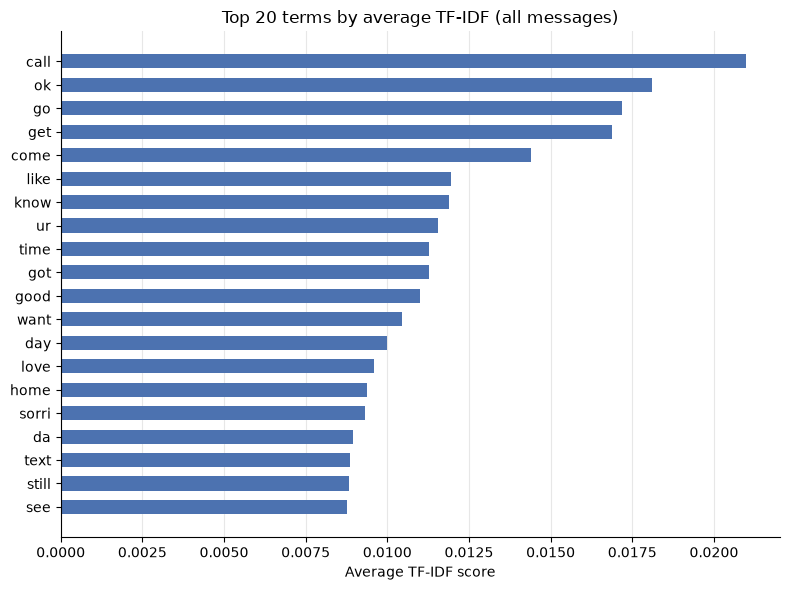

In [39]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top20["term"], top20["avg_tfidf"], color="#4C72B0", height=0.6)
ax.invert_yaxis()
ax.set_xlabel("Average TF-IDF score")
ax.set_title("Top 20 terms by average TF-IDF (all messages)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [40]:
def top_terms(matrix, n=20):
    avg = np.asarray(matrix.mean(axis=0)).ravel()
    return (
        pd.DataFrame({"term": terms, "avg_tfidf": avg})
          .sort_values("avg_tfidf", ascending=False)
          .head(n)
          .reset_index(drop=True)
    )

is_spam = (df["label"] == "spam").to_numpy()

top_spam = top_terms(X[is_spam])
top_ham = top_terms(X[~is_spam])

pd.concat([top_spam.add_prefix("spam_"), top_ham.add_prefix("ham_")], axis=1)

,spam_term,spam_avg_tfidf,ham_term,ham_avg_tfidf
0,call,0.063218,ok,0.020692
1,free,0.044226,go,0.018862
2,txt,0.036688,get,0.017163
3,text,0.032652,come,0.016403
4,mobil,0.030567,call,0.014434
5,stop,0.028171,like,0.013276
6,claim,0.027618,know,0.012918
7,repli,0.025415,got,0.012825
8,prize,0.024804,time,0.012384
9,ur,0.023643,good,0.012301


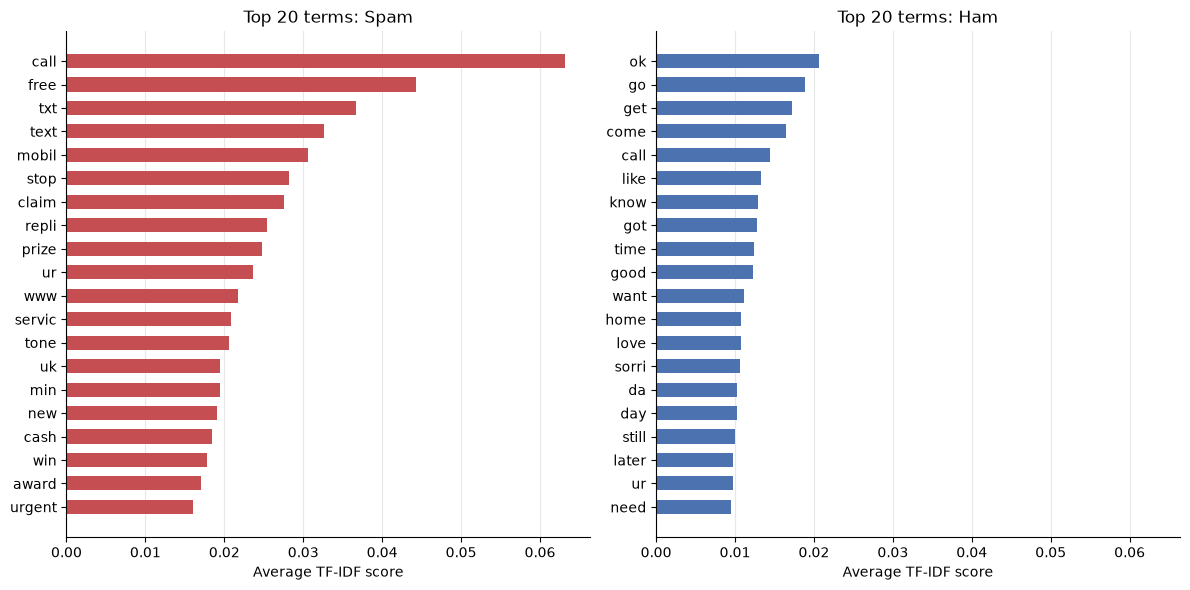

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True)

for ax, data, label, colour in zip(
    axes,
    [top_spam, top_ham],
    ["Spam", "Ham"],
    ["#C44E52", "#4C72B0"],
):
    ax.barh(data["term"], data["avg_tfidf"], color=colour, height=0.6)
    ax.invert_yaxis()
    ax.set_title(f"Top 20 terms: {label}")
    ax.set_xlabel("Average TF-IDF score")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [42]:
tfidf_v2 = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.05,        # changed from 0.9
    max_features=3000,
)

X_v2 = tfidf_v2.fit_transform(df["clean"])
print(X_v2.shape)

(5572, 3000)


In [43]:
terms_v2 = tfidf_v2.get_feature_names_out()
avg_v2 = np.asarray(X_v2.mean(axis=0)).ravel()

top20_v2 = (
    pd.DataFrame({"term": terms_v2, "avg_tfidf": avg_v2})
      .sort_values("avg_tfidf", ascending=False)
      .head(20)
      .reset_index(drop=True)
)
top20_v2

,term,avg_tfidf
0,like,0.012040
1,know,0.011966
2,time,0.011507
3,got,0.011398
4,good,0.011196
5,want,0.010573
6,day,0.010075
7,home,0.009655
8,love,0.009647
9,sorri,0.009529


In [44]:
gone = [t for t in top20["term"] if t not in tfidf_v2.vocabulary_]
gone

['call', 'ok', 'go', 'get', 'come', 'ur']